## 4.Hur ser en typisk order ut?

Den här delen analyserar ordervärden: genomsnittligt ordervärde (AOV) och spridning.

- AOV:** cirka 1 401 kr per order
- Median:** cirka 1 089 kr, vilket är en mer typisk order
- Spridning:** ordervärden varierar från 50 kr till 9 193 kr
- Avvikande ordrar:** 111 ordrar (cirka 4 %) är över 3 845 kr och höjer medelvärdet
- Datakvalitet:** inga saknade värden, inga dubbletter, och `revenue` stämmer med `price * units`

In [1]:
import pandas as pd

df = pd.read_csv("../data/ecommerce_sales.csv")
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [2]:
df.shape

(2500, 7)

In [3]:
df["order_id"].is_unique

True

In [4]:
aov = df["revenue"].sum() / df["order_id"].nunique()
aov

round(aov, 2)

np.float64(1401.11)

In [5]:
round(df["revenue"].mean(), 2) , round (df["revenue"].median(), 2)


(np.float64(1401.11), np.float64(1088.69))

In [6]:
df["revenue"].describe().round(2)

count    2500.00
mean     1401.11
std      1166.94
min        50.00
25%       577.96
50%      1088.69
75%      1884.75
max      9192.60
Name: revenue, dtype: float64

In [7]:
q1 = df["revenue"].quantile(0.25)
q3 = df["revenue"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

outliers = df[df["revenue"]> upper_limit]
upper_limit,len(outliers)


(np.float64(3844.935), 111)

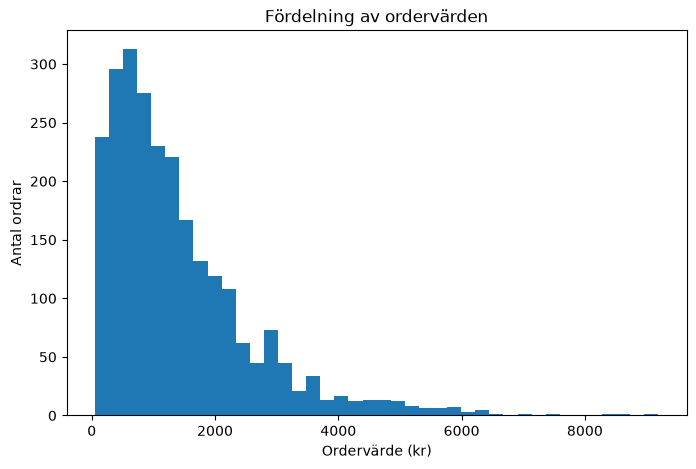

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["revenue"], bins = 40)
plt.title("Fördelning av ordervärden")
plt.xlabel("Ordervärde (kr)")
plt.ylabel("Antal ordrar")
plt.show()

## Histogrammet visar fördelningen av ordervärden. 
- De flesta ordrar ligger mellan 0 och 2 000 kr, och de vanligaste värdena ligger kring 500 till 800 kr. Den långa svansen åt höger visar att ett fåtal mycket stora ordrar höjer medelvärdet (AOV) över medianen.

C:\Users\roshi\AppData\Local\Temp\ipykernel_29436\2581671775.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["revenue"], vert = False)


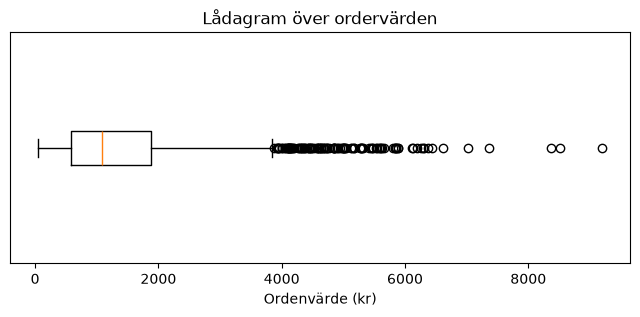

In [9]:
plt.figure(figsize =(8, 3))
plt.boxplot(df["revenue"], vert = False)
plt.title("Lådagram över ordervärden")
plt.xlabel("Ordenvärde (kr)")
plt.yticks([])
plt.show()

In [10]:
def compute_aov(df):
    return df["revenue"].sum()/df["order_id"].nunique()

def find_outliers(df):
    q1 = df["revenue"].quantile(0.25)
    q3 = df["revenue"].quantile(0.75)
    upper_limit = q3 + 1.5 * (q3 - q1)
    return df[df["revenue"] > upper_limit]

print(round(compute_aov(df), 2))
print(len(find_outliers(df)))

1401.11
111


In [11]:
def order_spread(df):
    return df["revenue"].describe().round(2)

order_spread(df)

count    2500.00
mean     1401.11
std      1166.94
min        50.00
25%       577.96
50%      1088.69
75%      1884.75
max      9192.60
Name: revenue, dtype: float64

In [12]:
print(df.isna().sum())
print("Dubbletter:",df.duplicated().sum())
diff = (df["price"]*df["units"] - df["revenue"]).abs()
print("Rader där revenue inte stämmer:", (diff>0.01).sum())

order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Dubbletter: 0
Rader där revenue inte stämmer: 0
